<a href="https://colab.research.google.com/github/VY-MS123/NTUC_Capstone_MarketAnalysis/blob/main/Capstone_Market.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
# Replace with your actual URL (ensure it's a direct link to the CSV file)
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'

df = pd.read_csv(url)

# Display the first few rows
df.head()

,customer_id,first_name,last_name,gender,age,country,income
0,CS00001,Isadora,Porto,Female,19,Brazil,117196
1,CS00002,Hugo,Carreño,Male,33,Chile,49256
2,CS00003,René,Olivera,Male,65,Mexico,33434
3,CS00004,Luiz Henrique,Pinto,Male,55,Brazil,75302
4,CS00005,Leonardo,Monteiro,Male,19,Brazil,32280


In [ ]:
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

df = pd.read_csv(url)

df.head()

,order_id,customer_id,product_name,description,price,discount,tax,order_date,quantity,shipping_cost,shipping_date
0,ODSHP00001,CS00001,Furniture,Transform your space with this stylish and fun...,645.52,0.37,0.02,26-05-2020,9,8.91,29-05-2020
1,ODSHP00002,CS00002,Dress,Look and feel your best with this elegant dress.,28.90,0.05,0.02,29-12-2022,9,13.95,29-12-2022
2,ODSHP00003,CS00003,Furniture,Transform your space with this stylish and fun...,3536.49,0.21,0.04,06-03-2021,3,36.42,06-03-2021
3,ODSHP00004,CS00004,Shoes,Step out in style with these fashionable shoes.,97.80,0.11,0.08,11-03-2020,7,9.35,13-03-2020
4,ODSHP00005,CS00005,Rugs,Add warmth and texture to your floors with the...,1785.38,0.13,0.00,12-03-2022,7,8.55,15-03-2022


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       50000 non-null  object 
 1   customer_id    50000 non-null  object 
 2   product_name   50000 non-null  object 
 3   description    50000 non-null  object 
 4   price          50000 non-null  float64
 5   discount       50000 non-null  float64
 6   tax            50000 non-null  float64
 7   order_date     50000 non-null  object 
 8   quantity       50000 non-null  int64  
 9   shipping_cost  50000 non-null  float64
 10  shipping_date  50000 non-null  object 
dtypes: float64(4), int64(1), object(6)
memory usage: 4.2+ MB


In [ ]:
df.isnull().sum()


,0
order_id,0
customer_id,0
product_name,0
description,0
price,0
discount,0
tax,0
order_date,0
quantity,0
shipping_cost,0


In [ ]:
#change the Data type
columns_to_convert = ['order_id', 'customer_id', 'product_name']
df[columns_to_convert] = df[columns_to_convert].astype('string')

In [ ]:
columns_to_convert = ['description']
df[columns_to_convert] = df[columns_to_convert].astype('string')

In [ ]:
columns_to_convert = ['order_date', 'shipping_date']
for col in columns_to_convert:
    df[col] = pd.to_datetime(df[col], format='%d-%m-%Y')

In [ ]:
#recheck data
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       50000 non-null  string        
 1   customer_id    50000 non-null  string        
 2   product_name   50000 non-null  string        
 3   description    50000 non-null  string        
 4   price          50000 non-null  float64       
 5   discount       50000 non-null  float64       
 6   tax            50000 non-null  float64       
 7   order_date     50000 non-null  datetime64[ns]
 8   quantity       50000 non-null  int64         
 9   shipping_cost  50000 non-null  float64       
 10  shipping_date  50000 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(4), int64(1), string(4)
memory usage: 4.2 MB


In [9]:
total_revenue = df["price"].sum()
total_orders = df["quantity"].sum()
avg_order_value = df["price"].mean()

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Units Sold: {total_orders:,}")
print(f"Average Sales Value per Item: ${avg_order_value:,.2f}")

Total Revenue: $63,796,343.63
Total Units Sold: 274,878
Average Sales Value per Item: $1,275.93


/tmp/ipykernel_1272/2673792549.py:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_sales = df.resample("M", on="order_date")["price"].sum().reset_index()


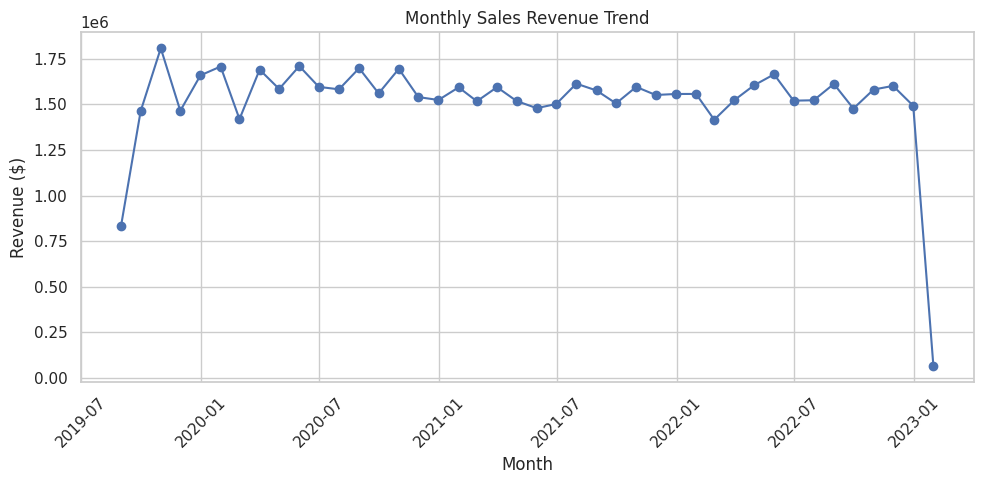

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd

# Define the URL and parse order_date as datetime directly
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df = pd.read_csv(url, parse_dates=['order_date'], dayfirst=True)

# Group by month
monthly_sales = df.resample("M", on="order_date")["price"].sum().reset_index()

# Plot Monthly Trend
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales["order_date"],
    monthly_sales["price"],
    marker="o",
    color="b",
    linestyle="-",
)
plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

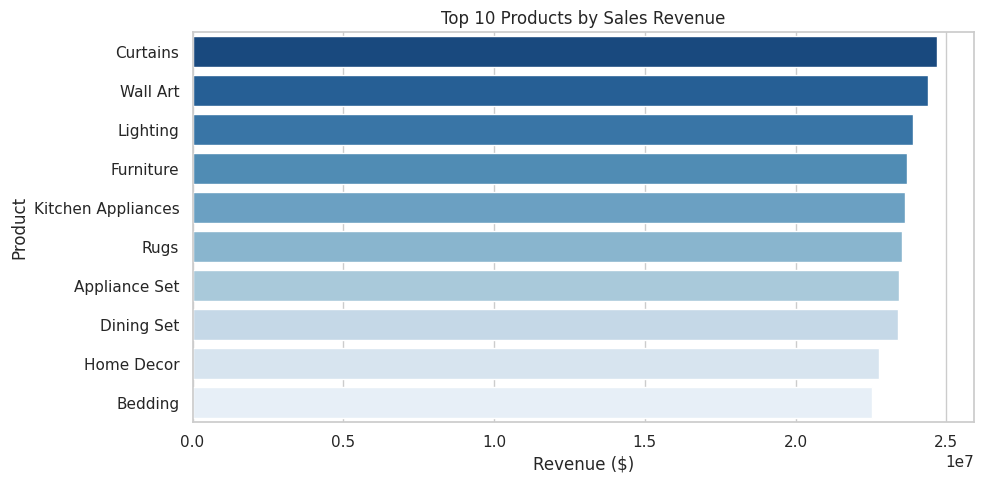

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate TotalSales
df["TotalSales"] = df["quantity"] * df["price"]

# Top 10 products by revenue
top_products = (
    df.groupby("product_name")["TotalSales"].sum().nlargest(10).reset_index()
)

# Plot Top Products
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_products,
    x="TotalSales",
    y="product_name",
    hue="product_name",
    palette="Blues_r",
    legend=False
)
plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Revenue ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()